# 한국장 MOM+PAIR 5:5 — **매 영업일 1개 신규 슬리브, 20영업일 보유** (CPU)

**반드시 매 KRX 거래일 종가로 포트폴리오 신호를 생성합니다.** 다음 영업일 **시가에 새로운 슬리브 1개(초기 자본의 1/20)**를 투자하고, 각 슬리브는 **20거래일 후의 시가**에 교체합니다. 즉 20개 슬리브가 겹쳐 운용됩니다. 첫 20거래일 동안은 미투자 슬리브가 현금으로 남고, 그다음부터 매일 가장 오래된 슬리브 하나를 교체합니다.

슬리브 20개를 한꺼번에 구성하거나 20일 간격으로만 신호를 생성하는 백테스트가 아닙니다. 아래 **`SMOKE_TEST=False`가 정식 전체 일별 백테스트**입니다. `SMOKE_TEST=True`는 동작 확인을 위해 처음 일부 날짜만 돌리는 별도 단축 모드이며, 실험 결과로 해석하면 안 됩니다.

STABLE 추론·PAIR(F−M)·MOM 50:50·기존 위험 최적화는 유지하고, CPU만 사용합니다. 종가 기준으로 신호를 만들되 매매는 반드시 다음 영업일의 **시가**로 체결합니다. `kr_pair_cpu.py` 및 `kr_pair_core.py`와 같은 폴더에서 실행하세요.

**증분 캐시 정책:** 최초 1회 과거 피처·Kalman 상태(계수·공분산·관측 횟수)를 `data/kr/live_cache/features/panels/kr_causal_features_incremental_v3.npz`에 저장합니다. 이후에는 **이미 저장된 기간을 재계산하지 않고** 필요한 신규 거래일만 120일 롤링 워밍업과 함께 이어서 생성합니다. 같은 기간 또는 이전 날짜 요청 시 `[features-cache] HIT`, 이후 날짜 요청 시 `[features-cache] EXTEND`가 표시됩니다. 44종목 가격이나 매크로의 **과거 값이 수정된 경우에만** 정확성을 위해 전체 재계산합니다. 예전 V2 패널에는 Kalman 공분산 상태가 없어 최초 전환 시 1회 복구 계산이 필요합니다. 추론 시나리오 NPZ 역시 입력·모델·시드가 같으면 재사용합니다.


In [1]:
# 1. 환경과 경로 (설치 명령은 자동 실행하지 않습니다)
from pathlib import Path
import os, sys, json, time
os.environ['CUDA_VISIBLE_DEVICES'] = ''
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

KIT_DIR = Path.cwd().resolve()  # 필요한 경우 이 값을 zip을 푼 디렉터리로 교체
PROJECT = KIT_DIR  # Windows diffusion 폴더 기준. 체크포인트: checkpoints/kr/stable_best.pt
assert (KIT_DIR/'kr_pair_cpu.py').is_file(), f'Cannot find code: {KIT_DIR}'
assert (PROJECT/'checkpoints/kr/stable_best.pt').is_file(), 'diffusion/checkpoints/kr/stable_best.pt 에 한국 모델을 넣으세요'
sys.path.insert(0,str(KIT_DIR))
import kr_pair_cpu as kr
import kr_pair_core as core
print('Project:', PROJECT)
print('Code:', KIT_DIR)
print('Torch:',kr.torch.__version__,'CUDA masked:',os.environ['CUDA_VISIBLE_DEVICES']=='')

Project: C:\Users\whd80\Desktop\4-2\AI_Capstone\src\diffusion
Code: C:\Users\whd80\Desktop\4-2\AI_Capstone\src\diffusion
Torch: 2.15.0+cpu CUDA masked: True


## 1. 오프라인 기본 검증

네트워크와 실제 체크포인트 없이 실행 가능한 테스트입니다. 미래 자료가 과거 피처에 스며들지 않는지, 슬리브가 다음 시가에 체결되는지, CPU 모델 실행이 가능한지 확인합니다.

In [2]:
from test_kr_pair_cpu import (
    test_time_gate, test_self_financing, test_20_sleeves_open,
    test_no_future_bootstrap, test_cpu_model_ddim,
)
for test in (test_time_gate, test_self_financing, test_20_sleeves_open,
             test_no_future_bootstrap, test_cpu_model_ddim):
    test()
    print('PASS', test.__name__)

PASS test_time_gate
PASS test_self_financing
PASS test_20_sleeves_open
PASS test_no_future_bootstrap
PASS test_cpu_model_ddim


## 2. 요청 시간에 대한 개별 인퍼런스 → JSON

`ASOF`는 KST로 지정합니다. `YYYY-MM-DD`만 넣으면 자동으로 **18:30 KST** 요청으로 해석합니다. 장 마감 이후 Yahoo 최신 44종목 종가와 코스피 지수가 확인되면 인퍼런스를 허용합니다. 장중·미래시간·해당일 비거래일·불완전 데이터는 **거부**합니다.

전처리 배열에 요청 날짜와 44개 종목이 있으면 그대로 사용하고, 없는 경우 첫 120관측을 포함하는 과거 데이터로 Kalman β를 부트스트랩합니다. 새로운 날짜를 계산할 때 미래 20일 수익률이나 테스트 split 레이블은 사용하지 않습니다.

**최초에는 `RUN_INFER=False`입니다.** 바꾼 뒤 이 셀을 실행하세요.

In [3]:
ASOF = '2026-06-30T18:30:00+09:00'  # 자유롭게 변경: 예) '2026-11-02T18:30:00+09:00'
RUN_INFER = False
FETCH_DATA = True     # 처음 실행하면 2012년~요청일 44종목·매크로 전량 다운로드
FORCE_REFRESH = False # 기존 아카이브 날짜도 새로 조회하려면 True
K = 128               # 논문과 동일한 K; CPU 연산량에 직접적인 영향
SEED = 0              # 재현 가능한 한 개의 inference seed
CPU_THREADS = 4
CPU_BATCH = 128
BLEND_MODE = 'smooth050' # 고정 0.5*MOM_rank_z + 0.5*PAIR_rank_z
REQUIRE_REPAIR = False # True면 위험 보정 최적화 실패 시 JSON 생성 중단

if RUN_INFER:
    signal = kr.infer(PROJECT,ASOF,fetch=FETCH_DATA,force=FORCE_REFRESH,
                      K=K,seed=SEED,batch=CPU_BATCH,threads=CPU_THREADS,
                      blend=BLEND_MODE,require_repair=REQUIRE_REPAIR)
    print('Saved:',PROJECT/'results/kr_pair_cpu/signals'/f"{signal['date'].replace('-','')}_s{SEED:03d}.json")
    display(pd.DataFrame([{'ticker':k,'weight':v} for k,v in signal['weights'].items()]).sort_values('weight',ascending=False))
    print(json.dumps({k:v for k,v in signal.items() if k not in ('weights','weights_pct')},ensure_ascii=False,indent=2))
else:
    print('RUN_INFER=False — 시간과 설정을 확인하고 True로 변경하세요')

RUN_INFER=False — 시간과 설정을 확인하고 True로 변경하세요


## 3. 20슬리브 — **매 거래일 새 포트폴리오 1개**

- **신호 주기: 1거래일.** 월요일 종가에 만든 포트폴리오는 화요일 시가에 신규 슬리브 1개로 매수합니다. 화요일 종가에 다시 새 포트폴리오를 만들고 수요일 시가에 다음 슬리브를 매수합니다.
- **보유 기간: 20거래일.** 슬리브 0, 1, ..., 19 순서로 배정하고 21번째 매수일에는 **슬리브 0을 매도·재매수**합니다. 이 방식으로 매 영업일 신규 신호가 운용됩니다.
- 기존 20개 슬리브의 평가액은 매일 종가로 합산해 NAV를 계산합니다. 최초 슬리브가 모두 채워질 때까지 현금 비중이 높아지는 것은 정상입니다.
- 편도 `FEE_BPS_SIDE` 거래 비용을 매수·매도 모두에 부과합니다. 소수점 주식 체결, 시가 체결 가능, 시장 충격 없음 등은 백테스트 가정입니다.
- **백테스트 기간:** `BACKTEST_START`의 첫 KRX 거래일부터 `BACKTEST_END`의 마지막 거래일까지입니다. 그 이전의 긴 피처 부트스트랩 기간은 NAV에 포함하지 않습니다.
- 과거 44종목의 시가 데이터는 자동 수집합니다. 종가와 시가의 조정 단위가 일치하도록 변환하며 시가 데이터 누락을 종가로 대체하지 않습니다.
- CPU DDIM 경로는 날짜·시드·K별 캐시 재사용이 가능합니다. 전체 일별 K=128은 계산량이 많습니다.

**기본 설정은 `SMOKE_TEST=False` (매일 전체 실행)**입니다. 간단한 사전 점검만 하려면 `SMOKE_TEST=True`로 바꾸세요. 점검 결과는 투자 성과가 아닙니다.

- `[features-cache] HIT`: 디스크의 기존 기간 그대로 사용. `[features-cache] EXTEND`: 마지막 저장 거래일 이후만 생성. `[features-cache] SAVED`: 증분 업데이트 원자적 저장. 과거 가격/매크로 수정 시에만 전체 재계산합니다. `FORCE_REFRESH=True`는 가격 재확인용이므로 평상시에는 `False`를 사용하세요.


In [8]:
# 3. 매 영업일 종가 신호 → 다음 영업일 시가에 신규 슬리브 1개
BACKTEST_START = '2024-10-01'
BACKTEST_END   = '2026-06-30'
RUN_BACKTEST = True
SMOKE_TEST = False           # False: 전체 거래일 매일 생성 / True: 처음 22개 신호만 점검
SLEEVES = 20
FEE_BPS_SIDE = 20.0         # 편도 20bp
K_BACKTEST = 2 if SMOKE_TEST else 128
MAX_SIGNALS = 22 if SMOKE_TEST else None  # 22면 20개 슬리브가 첫 순환을 완성하는지 확인 가능

if RUN_BACKTEST:
    t0=time.time()
    nav,trades,metrics,outdir=kr.backtest(
        PROJECT,BACKTEST_START,BACKTEST_END,
        fetch=FETCH_DATA,force=FORCE_REFRESH,
        K=K_BACKTEST,seed=SEED,batch=CPU_BATCH,threads=CPU_THREADS,
        blend=BLEND_MODE,require_repair=REQUIRE_REPAIR,
        sleeves=SLEEVES,fee_bps_side=FEE_BPS_SIDE,max_signals=MAX_SIGNALS)
    print('Result directory:',outdir,'elapsed_s:',round(time.time()-t0,1))
    print(json.dumps(metrics,ensure_ascii=False,indent=2))
    display(trades[['decision_date','entry_date','sleeve','account_before_open','fee']].head(25))
    print(f"매일 신호 {metrics['decisions']}회 → 다음 거래일 시가 체결 {len(trades)}회")
else:
    print('RUN_BACKTEST=False')


[backtest] loading KR close through 2026-06-30, Yahoo OPEN history starting 2024-10-01
[features-cache] HIT through 2026-06-29 (3431 existing sessions)
[backtest] 5/421 signals, last=2024-10-10
[backtest] 10/421 signals, last=2024-10-17
[backtest] 15/421 signals, last=2024-10-24
[backtest] 20/421 signals, last=2024-10-31
[backtest] 25/421 signals, last=2024-11-07
[backtest] 30/421 signals, last=2024-11-14
[backtest] 35/421 signals, last=2024-11-21
[backtest] 40/421 signals, last=2024-11-28
[backtest] 45/421 signals, last=2024-12-05
[backtest] 50/421 signals, last=2024-12-12
[backtest] 55/421 signals, last=2024-12-19
[backtest] 60/421 signals, last=2024-12-27
[backtest] 65/421 signals, last=2025-01-07
[backtest] 70/421 signals, last=2025-01-14
[backtest] 75/421 signals, last=2025-01-21
[backtest] 80/421 signals, last=2025-02-03
[backtest] 85/421 signals, last=2025-02-10
[backtest] 90/421 signals, last=2025-02-17
[backtest] 95/421 signals, last=2025-02-24
[backtest] 100/421 signals, last

KeyboardInterrupt: 

## 4. 백테스트 무결성 검사 및 NAV

신호를 생성한 **모든 거래일**에 대해 다음 거래일 시가에 슬리브가 정확히 하나씩 배정됐는지 검사합니다. 최초 20일과 그다음 재활용 순서(`0,1,...,19,0,1,...`)를 확인하고, 슬리브 0의 두 체결일이 정확히 **20거래일 간격**인지 검증합니다. 시각화는 전체 기간의 종가 NAV를 보여줍니다.


,nav,daily_return,fee,turnover,active_sleeves,idle_cash
date,,,,,,
2025-03-25,1.159645,-0.003952,0.000122,0.061023,20,0.0
2025-03-26,1.163144,0.003017,0.000095,0.047444,20,0.0
2025-03-27,1.140717,-0.019281,0.000098,0.048905,20,0.0
2025-03-28,1.114579,-0.022914,0.000090,0.044901,20,0.0
2025-03-31,1.097939,-0.014929,0.000087,0.043469,20,0.0


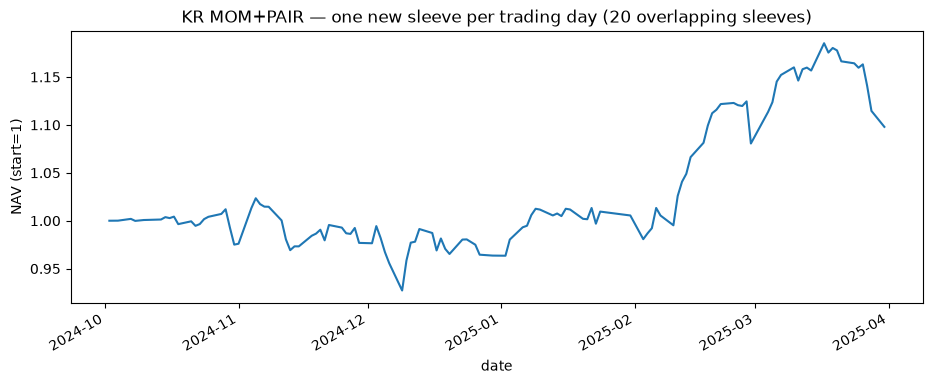

PASS: 매 영업일 1개 신호, 다음 시가 체결, 20거래일마다 같은 슬리브 교체


In [5]:
if 'nav' in globals() and len(nav):
    display(nav.tail(5))
    ax=nav.nav.plot(figsize=(11,4),title='KR MOM+PAIR — one new sleeve per trading day (20 overlapping sleeves)')
    ax.set_ylabel('NAV (start=1)')
    plt.show()

    assert len(trades)==metrics['decisions'], '신호일과 실제 체결 횟수가 다릅니다.'
    assert not metrics['unexecuted_signals'], '미체결 신호가 존재합니다.'
    assert trades['sleeve'].between(0,SLEEVES-1).all()
    assert (trades['sleeve'].to_numpy(dtype=int)==np.arange(len(trades))%SLEEVES).all(), '슬리브 순환 순서 오류'
    signal_days=pd.DatetimeIndex(pd.to_datetime(trades['decision_date']))
    fill_days=pd.DatetimeIndex(pd.to_datetime(trades['entry_date']))
    assert signal_days.equals(nav.index[:len(trades)]), '매 거래일 종가에 신호가 생성되지 않았습니다.'
    assert fill_days.equals(nav.index[1:len(trades)+1]), '신호 다음 거래일 시가에 체결되지 않았습니다.'
    assert (nav.nav>0).all() and np.isfinite(nav.nav).all()
    if len(trades)>SLEEVES:
        assert trades.sleeve.iloc[0]==trades.sleeve.iloc[SLEEVES]==0
        assert nav.index.get_loc(fill_days[SLEEVES])-nav.index.get_loc(fill_days[0])==SLEEVES
    print('PASS: 매 영업일 1개 신호, 다음 시가 체결, 20거래일마다 같은 슬리브 교체')
else:
    print('먼저 백테스트 셀을 실행하세요.')


## 5. 저장 결과

- `results/kr_pair_cpu/backtests/<기간>_s000_smooth050/daily_weights.csv` : **매 영업일마다 생성한** 44종목 포트폴리오 목표 비중
- `results/kr_pair_cpu/backtests/<기간>_s000_smooth050/trades.csv` : **매 영업일 다음 시가** 신규 슬리브 매수/교체 기록 (`sleeve`는 0~19 반복)
- `results/kr_pair_cpu/backtests/<기간>_s000_smooth050/nav.csv` : 매 거래일 종가 NAV 및 활성 슬리브 수
- `results/kr_pair_cpu/backtests/<기간>_s000_smooth050/metrics.json` : 전체 기간 성과 및 거래 횟수

**주의:** `SMOKE_TEST=True`는 매우 짧은 검증 구간만 시뮬레이션하므로 샤프·수익률을 실제 백테스트 결과로 해석하면 안 됩니다. 종가 신호는 하루 뒤 시가 체결을 가정하고, 2025-03-31 기준 고정 종목군의 생존편향과 Yahoo 조정 시가 근사·매매 가능성 한계를 갖습니다.
